In [1]:
# Cell 1: Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [2]:
# Cell 2: Load the cleaned data and standardize station names
# Locate the GitHub repository
current = Path.cwd().resolve()
if (current / "data").is_dir():
    PROJECT_ROOT = current
elif (current.parent / "data").is_dir():
    PROJECT_ROOT = current.parent
else:
    raise FileNotFoundError("Could not find the project data folder.")
# Load the cleaned dataset directly from ZIP
processed_path = (
    PROJECT_ROOT / "data" / "processed"
    / "Cleaned data.zip"
)
df = pd.read_csv(
    processed_path,
    compression="zip",
    low_memory=False
)
print("Dataset loaded from:", processed_path)
df["Start Date"] = pd.to_datetime(df["Start Date"], format="mixed", errors="coerce")
df["End Date"] = pd.to_datetime(df["End Date"], format="mixed", errors="coerce")
assert df["Start Date"].notna().all() and df["End Date"].notna().all()
print("Charging sessions:", len(df))
print("Original station names:", df["Station Name"].nunique())

df["Station Name"] = (
    df["Station Name"]
    .str.upper()
    .str.replace(r"\s*/\s*", " / ", regex=True)
    .str.replace(r"\s*#\s*", " #", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Number of stations:", df["Station Name"].nunique())


Dataset loaded from: C:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\BA\Project\DTU-Business-Analytics-2026\data\processed\Cleaned data.zip
Charging sessions: 258950
Original station names: 47
Number of stations: 46


In [3]:
# Cell 3: Allocate session energy to hourly intervals

# Convert charging time into seconds
charging_seconds = np.rint(
    df["Charging Time Hours"].to_numpy() * 3600
).astype(np.int64)

# Convert start timestamps into seconds
start_seconds = (
    df["Start Date"].to_numpy(dtype="datetime64[s]")
    .astype(np.int64)
)

# Assume charging starts when the vehicle is plugged in
end_seconds = start_seconds + charging_seconds

# Find how many hourly intervals each session covers
hours_per_session = (
    (end_seconds - 1) // 3600
    - start_seconds // 3600
    + 1
)

# Repeat each session for every hourly interval it covers
session_index = np.repeat(
    np.arange(len(df)), hours_per_session
)

hour_number = (
    np.arange(len(session_index))
    - np.repeat(
        np.cumsum(hours_per_session) - hours_per_session,
        hours_per_session
    )
)

# Calculate the beginning of each hourly interval
hour_start = (
    (start_seconds[session_index] // 3600) * 3600
    + hour_number * 3600
)

# Calculate the actual charging time within each hour
overlap_seconds = (
    np.minimum(hour_start + 3600, end_seconds[session_index])
    - np.maximum(hour_start, start_seconds[session_index])
)

# Distribute session energy proportionally across hours
hourly_energy = (
    df["Energy (kWh)"].to_numpy()[session_index]
    * overlap_seconds
    / charging_seconds[session_index]
)

# Create hourly dataset
hourly_df = pd.DataFrame({
    "Station Name": df["Station Name"].to_numpy()[session_index],
    "Hour": pd.to_datetime(hour_start, unit="s"),
    "Energy (kWh)": hourly_energy
})

# Combine sessions occurring at the same station and hour
hourly_df = (
    hourly_df.groupby(["Station Name", "Hour"], as_index=False)
    ["Energy (kWh)"].sum()
    .sort_values(["Station Name", "Hour"])
    .reset_index(drop=True)
)

# Check that total energy has been preserved
print("Original energy (kWh):", df["Energy (kWh)"].sum())
print("Hourly energy (kWh):", hourly_df["Energy (kWh)"].sum())
print("Number of hourly records:", len(hourly_df))

display(hourly_df.head(10))


Original energy (kWh): 2211609.4159740005
Hourly energy (kWh): 2211609.4159739995
Number of hourly records: 578398


,Station Name,Hour,Energy (kWh)
0,PALO ALTO CA / BRYANT #1,2011-10-13 12:00:00,0.668822
1,PALO ALTO CA / BRYANT #1,2011-10-13 13:00:00,0.961686
2,PALO ALTO CA / BRYANT #1,2011-10-13 18:00:00,0.683024
3,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00,3.725587
4,PALO ALTO CA / BRYANT #1,2011-10-13 20:00:00,2.222933
5,PALO ALTO CA / BRYANT #1,2011-10-14 14:00:00,0.859986
6,PALO ALTO CA / BRYANT #1,2011-10-14 15:00:00,3.685652
7,PALO ALTO CA / BRYANT #1,2011-10-14 16:00:00,1.713828
8,PALO ALTO CA / BRYANT #1,2011-10-15 12:00:00,1.545526
9,PALO ALTO CA / BRYANT #1,2011-10-15 13:00:00,2.897861


### Assumptions in hourly energy allocation

Charging sessions contain total energy rather than measured consumption for each hour. The hourly series therefore allocates each session's recorded energy proportionally across the hours in its assumed charging interval, equivalent to assuming a constant average charging rate during that interval.

For sessions that cross midnight, the resulting hourly consumption may depend on a final session total that was not yet available at the forecast cutoff. Accordingly, these experiments evaluate **day-ahead predictions of retrospectively reconstructed hourly energy consumption**, not a fully real-time, cutoff-safe forecasting system. This limitation should be considered when interpreting operational applicability.

In [4]:
# Cell 4: Inspect inactivity gaps before assigning zero consumption

# Sort observations chronologically for each station
hourly_sorted = hourly_df.sort_values(
    ["Station Name", "Hour"]
).copy()

# Calculate hours since the previous recorded charging hour
hourly_sorted["Gap Hours"] = (
    hourly_sorted.groupby("Station Name")["Hour"]
    .diff()
    .dt.total_seconds() / 3600 - 1
)

# Identify gaps longer than 7 and 30 days
gap_summary = hourly_sorted.groupby("Station Name").agg(
    Max_Gap_Hours=("Gap Hours", "max"),
    Gaps_Over_7_Days=("Gap Hours", lambda x: (x > 168).sum()),
    Gaps_Over_30_Days=("Gap Hours", lambda x: (x > 720).sum())
)

# Convert maximum gap into days
gap_summary["Max_Gap_Days"] = (
    gap_summary["Max_Gap_Hours"] / 24
)

# Display stations with the longest gaps
display(
    gap_summary.sort_values(
        "Max_Gap_Days", ascending=False
    ).head(15).round(2)
)


,Max_Gap_Hours,Gaps_Over_7_Days,Gaps_Over_30_Days,Max_Gap_Days
Station Name,,,,
PALO ALTO CA / MPL #1,2956.0,48,7,123.17
PALO ALTO CA / MPL #3,2855.0,40,6,118.96
PALO ALTO CA / MPL #2,2717.0,43,5,113.21
PALO ALTO CA / MPL #5,1979.0,3,2,82.46
PALO ALTO CA / MPL #6,1975.0,2,1,82.29
PALO ALTO CA / MPL #4,1388.0,6,3,57.83
PALO ALTO CA / BRYANT #1,1319.0,14,4,54.96
PALO ALTO CA / CAMBRIDGE #3,791.0,1,1,32.96
PALO ALTO CA / BRYANT #2,713.0,5,0,29.71


In [5]:
# Cell 5: Complete the hourly time series and fill unrecorded hours with zero

hourly_parts = []

for station, group in hourly_df.groupby("Station Name"):

    # Create all hourly timestamps between first and last observation
    all_hours = pd.date_range(
        start=group["Hour"].min(),
        end=group["Hour"].max(),
        freq="h"
    )

    # Fill hours without recorded charging with zero
    hourly_energy = (
        group.set_index("Hour")["Energy (kWh)"]
        .reindex(all_hours, fill_value=0)
    )

    # Store the continuous hourly series
    station_data = pd.DataFrame({
        "Station Name": station,
        "Hour": all_hours,
        "Energy (kWh)": hourly_energy.to_numpy()
    })

    hourly_parts.append(station_data)

# Combine all stations
hourly_complete = pd.concat(
    hourly_parts,
    ignore_index=True
)

# Verify the results
print("Number of stations:",
      hourly_complete["Station Name"].nunique())

print("Original hourly records:", len(hourly_df))
print("Complete hourly records:", len(hourly_complete))

print("Hours with zero consumption:",
      (hourly_complete["Energy (kWh)"] == 0).sum())

print("Total energy (kWh):",
      hourly_complete["Energy (kWh)"].sum())

display(hourly_complete.head(10))


Number of stations: 46
Original hourly records: 578398
Complete hourly records: 1533118
Hours with zero consumption: 954720
Total energy (kWh): 2211609.4159739995


,Station Name,Hour,Energy (kWh)
0,PALO ALTO CA / BRYANT #1,2011-10-13 12:00:00,0.668822
1,PALO ALTO CA / BRYANT #1,2011-10-13 13:00:00,0.961686
2,PALO ALTO CA / BRYANT #1,2011-10-13 14:00:00,0.000000
3,PALO ALTO CA / BRYANT #1,2011-10-13 15:00:00,0.000000
4,PALO ALTO CA / BRYANT #1,2011-10-13 16:00:00,0.000000
5,PALO ALTO CA / BRYANT #1,2011-10-13 17:00:00,0.000000
6,PALO ALTO CA / BRYANT #1,2011-10-13 18:00:00,0.683024
7,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00,3.725587
8,PALO ALTO CA / BRYANT #1,2011-10-13 20:00:00,2.222933
9,PALO ALTO CA / BRYANT #1,2011-10-13 21:00:00,0.000000


In [6]:
# Cell 6: Split observations chronologically into 70% training and 30% testing

# Sort observations chronologically
hourly_complete = hourly_complete.sort_values(
    ["Hour", "Station Name"]
).reset_index(drop=True)

# Count observations per calendar day
daily_counts = hourly_complete.groupby(
    hourly_complete["Hour"].dt.normalize()
).size()

# Find the day where we reach approximately 70% of observations
target = len(hourly_complete) * 0.70

split_position = np.searchsorted(
    daily_counts.cumsum().to_numpy(),
    target
)

split_date = daily_counts.index[split_position]

# Split at midnight to preserve full forecast days
train_df = hourly_complete[
    hourly_complete["Hour"] < split_date
].copy()

test_df = hourly_complete[
    hourly_complete["Hour"] >= split_date
].copy()

# Display results
print("Split date:", split_date)

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("Training percentage:",
      round(len(train_df) / len(hourly_complete) * 100, 2), "%")

print("Testing percentage:",
      round(len(test_df) / len(hourly_complete) * 100, 2), "%")

print("Training period:",
      train_df["Hour"].min(), "to", train_df["Hour"].max())

print("Testing period:",
      test_df["Hour"].min(), "to", test_df["Hour"].max())

print("Stations in training:",
      train_df["Station Name"].nunique())

print("Stations in testing:",
      test_df["Station Name"].nunique())

# Preserve the new-station distinction for the baseline and evaluation
train_stations = set(train_df["Station Name"])
test_stations = set(test_df["Station Name"])
print("Stations without training history:", len(test_stations - train_stations))


Split date: 2019-04-22 00:00:00
Training observations: 1073089
Testing observations: 460029
Training percentage: 69.99 %
Testing percentage: 30.01 %
Training period: 2011-07-29 20:00:00 to 2019-04-21 23:00:00
Testing period: 2019-04-22 00:00:00 to 2020-12-31 22:00:00
Stations in training: 33
Stations in testing: 46
Stations without training history: 13


In [8]:
# Cell 7: Build the station-weekday-hour historical-average baseline

# Create weekday and hour features
train_baseline = train_df.copy()
test_baseline = test_df.copy()

for data in [train_baseline, test_baseline]:
    data["Weekday"] = data["Hour"].dt.dayofweek
    data["HourOfDay"] = data["Hour"].dt.hour

# Historical average for each station, weekday and hour
station_average = (
    train_baseline.groupby(
        ["Station Name", "Weekday", "HourOfDay"]
    )["Energy (kWh)"]
    .mean()
    .reset_index(name="Station Average")
)

# General historical average for stations without training history
global_average = (
    train_baseline.groupby(
        ["Weekday", "HourOfDay"]
    )["Energy (kWh)"]
    .mean()
    .reset_index(name="Global Average")
)

# Add station-specific predictions to the test data
baseline_df = test_baseline.merge(
    station_average,
    on=["Station Name", "Weekday", "HourOfDay"],
    how="left"
)

# Add global averages as a fallback
baseline_df = baseline_df.merge(
    global_average,
    on=["Weekday", "HourOfDay"],
    how="left"
)

# Use station average when available, otherwise global average
baseline_df["Baseline Prediction"] = (
    baseline_df["Station Average"]
    .fillna(baseline_df["Global Average"])
)

# Identify stations without training history
baseline_df["Station Type"] = np.where(
    baseline_df["Station Name"].isin(train_stations),
    "Existing",
    "New"
)

# Check results
print("Total predictions:", len(baseline_df))

print("Missing predictions:",
      baseline_df["Baseline Prediction"].isna().sum())

print("\nStation types:")
print(baseline_df["Station Type"].value_counts())

display(baseline_df[[
    "Station Name",
    "Hour",
    "Energy (kWh)",
    "Baseline Prediction",
    "Station Type"
]].head(10))


Total predictions: 460029
Missing predictions: 0

Station types:
Station Type
Existing    457866
New           2163
Name: count, dtype: int64


,Station Name,Hour,Energy (kWh),Baseline Prediction,Station Type
0,PALO ALTO CA / BRYANT #1,2019-04-22,0.0,0.481803,Existing
1,PALO ALTO CA / BRYANT #2,2019-04-22,0.0,0.547811,Existing
2,PALO ALTO CA / BRYANT #3,2019-04-22,0.0,0.286546,Existing
3,PALO ALTO CA / BRYANT #4,2019-04-22,0.0,0.098745,Existing
4,PALO ALTO CA / BRYANT #5,2019-04-22,0.0,0.071905,Existing
5,PALO ALTO CA / BRYANT #6,2019-04-22,0.0,0.195733,Existing
6,PALO ALTO CA / CAMBRIDGE #1,2019-04-22,0.0,0.446758,Existing
7,PALO ALTO CA / CAMBRIDGE #2,2019-04-22,0.0,0.281144,Existing
8,PALO ALTO CA / CAMBRIDGE #3,2019-04-22,0.0,0.000000,Existing
9,PALO ALTO CA / CAMBRIDGE #4,2019-04-22,0.0,0.000000,Existing


In [9]:
# Cell 8: Create calendar and daily/weekly lag features

# Sort data chronologically for each station
forecast_df = hourly_complete.sort_values(
    ["Station Name", "Hour"]
).copy()

# Calendar features
forecast_df["Weekday"] = forecast_df["Hour"].dt.weekday
forecast_df["HourOfDay"] = forecast_df["Hour"].dt.hour
forecast_df["Month"] = forecast_df["Hour"].dt.month

# Historical consumption at the same hour yesterday
forecast_df["Lag_24h"] = (
    forecast_df.groupby("Station Name")["Energy (kWh)"]
    .shift(24)
)

# Historical consumption at the same hour last week
forecast_df["Lag_168h"] = (
    forecast_df.groupby("Station Name")["Energy (kWh)"]
    .shift(168)
)

# Check missing lag values
print("Missing 24-hour lag values:",
      forecast_df["Lag_24h"].isna().sum())

print("Missing 168-hour lag values:",
      forecast_df["Lag_168h"].isna().sum())

# Display the new features
display(forecast_df[[
    "Station Name",
    "Hour",
    "Energy (kWh)",
    "Weekday",
    "HourOfDay",
    "Month",
    "Lag_24h",
    "Lag_168h"
]].head(10))


Missing 24-hour lag values: 996
Missing 168-hour lag values: 6820


,Station Name,Hour,Energy (kWh),Weekday,HourOfDay,Month,Lag_24h,Lag_168h
4585,PALO ALTO CA / BRYANT #1,2011-10-13 12:00:00,0.668822,3,12,10,NaN,NaN
4590,PALO ALTO CA / BRYANT #1,2011-10-13 13:00:00,0.961686,3,13,10,NaN,NaN
4595,PALO ALTO CA / BRYANT #1,2011-10-13 14:00:00,0.000000,3,14,10,NaN,NaN
4600,PALO ALTO CA / BRYANT #1,2011-10-13 15:00:00,0.000000,3,15,10,NaN,NaN
4605,PALO ALTO CA / BRYANT #1,2011-10-13 16:00:00,0.000000,3,16,10,NaN,NaN
4610,PALO ALTO CA / BRYANT #1,2011-10-13 17:00:00,0.000000,3,17,10,NaN,NaN
4615,PALO ALTO CA / BRYANT #1,2011-10-13 18:00:00,0.683024,3,18,10,NaN,NaN
4620,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00,3.725587,3,19,10,NaN,NaN
4625,PALO ALTO CA / BRYANT #1,2011-10-13 20:00:00,2.222933,3,20,10,NaN,NaN
4630,PALO ALTO CA / BRYANT #1,2011-10-13 21:00:00,0.000000,3,21,10,NaN,NaN


In [10]:
# Cell 9: Prepare training and testing lag features without leakage

# Apply the same chronological split used for the baseline
forecast_train = forecast_df[
    forecast_df["Hour"] < split_date
].copy()

forecast_test = forecast_df[
    forecast_df["Hour"] >= split_date
].copy()

# Identify historical consumption features
lag_columns = ["Lag_24h", "Lag_168h"]

# Check missing lag values
print("Training observations:", len(forecast_train))
print("Testing observations:", len(forecast_test))

print("\nMissing values in training:")
print(forecast_train[lag_columns].isna().sum())

print("\nMissing values in testing:")
print(forecast_test[lag_columns].isna().sum())

# Check rows with complete lag information
print("\nTraining rows with complete lag features:",
      forecast_train[lag_columns].notna().all(axis=1).sum())

print("Testing rows with complete lag features:",
      forecast_test[lag_columns].notna().all(axis=1).sum())

# Calculate average hourly consumption for each station
station_means = (
    forecast_train.groupby("Station Name")["Energy (kWh)"]
    .mean()
)

# Calculate overall average from training data
global_mean = forecast_train["Energy (kWh)"].mean()

# Fill missing lag values in training and testing
for data in [forecast_train, forecast_test]:

    # Station average, or global average for new stations
    fallback = (
        data["Station Name"]
        .map(station_means)
        .fillna(global_mean)
    )

    for lag in ["Lag_24h", "Lag_168h"]:

        # Record which observations originally had missing values
        data[lag + "_Missing"] = data[lag].isna().astype(int)

        # Replace missing lag values
        data[lag] = data[lag].fillna(fallback)

# Verify results
print("Global training average (kWh):", round(global_mean, 3))

print("\nMissing lag values in training:")
print(forecast_train[["Lag_24h", "Lag_168h"]].isna().sum())

print("\nMissing lag values in testing:")
print(forecast_test[["Lag_24h", "Lag_168h"]].isna().sum())

print("\nTraining observations:", len(forecast_train))
print("Testing observations:", len(forecast_test))


Training observations: 1073089
Testing observations: 460029

Missing values in training:
Lag_24h      792
Lag_168h    5544
dtype: int64

Missing values in testing:
Lag_24h      204
Lag_168h    1276
dtype: int64

Training rows with complete lag features: 1067545
Testing rows with complete lag features: 458753
Global training average (kWh): 1.589

Missing lag values in training:
Lag_24h     0
Lag_168h    0
dtype: int64

Missing lag values in testing:
Lag_24h     0
Lag_168h    0
dtype: int64

Training observations: 1073089
Testing observations: 460029


In [27]:
# Model configurations for internal validation and final fitting
# Cell 10: Train original Gradient Boosting

from sklearn.ensemble import HistGradientBoostingRegressor

# Assign a numerical ID to each training station
station_mapping = {
    station: i
    for i, station in enumerate(
        sorted(forecast_train["Station Name"].unique())
    )
}

# Apply station IDs to training and testing data
# Unseen stations receive -1
forecast_train["Station Code"] = (
    forecast_train["Station Name"]
    .map(station_mapping)
    .fillna(-1)
    .astype(int)
)

forecast_test["Station Code"] = (
    forecast_test["Station Name"]
    .map(station_mapping)
    .fillna(-1)
    .astype(int)
)

# Select the predictor variables
features = [
    "Station Code",
    "Weekday",
    "HourOfDay",
    "Month",
    "Lag_24h",
    "Lag_168h",
    "Lag_24h_Missing",
    "Lag_168h_Missing"
]

# Training inputs and actual energy consumption
X_train = forecast_train[features]
y_train = forecast_train["Energy (kWh)"]

# Testing inputs
X_test = forecast_test[features]

# Create the prediction model
model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.07,
    max_leaf_nodes=25,
    categorical_features=[0],
    early_stopping=False,
    random_state=42
)


In [28]:
# Cell 11: Train Random Forest for comparison

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Select forecasting features
rf_features = [
    "Station Name",
    "Weekday",
    "HourOfDay",
    "Month",
    "Lag_24h",
    "Lag_168h",
    "Lag_24h_Missing",
    "Lag_168h_Missing"
]

# Identify categorical and numerical features
categorical_features = [
    "Station Name", "Weekday", "HourOfDay", "Month"
]

numerical_features = [
    "Lag_24h", "Lag_168h",
    "Lag_24h_Missing", "Lag_168h_Missing"
]

# Encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

# Create Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=60,
        max_depth=14,
        min_samples_leaf=20,
        max_features=0.7,
        max_samples=0.20,
        n_jobs=-1,
        random_state=42
    ))
])

### Internal validation and model selection

The original training period is divided chronologically into an earlier development period and a later internal validation period. The historical-average baseline, original Gradient Boosting, Random Forest, and extended Gradient Boosting approaches are evaluated on this internal validation split.

The Gradient Boosting settings (`max_iter=100`, `learning_rate=0.07`, `max_leaf_nodes=25`) and Random Forest settings are fixed in the code; **this notebook does not document a systematic hyperparameter search**. Validation results support comparison of the approaches, but the notebook alone cannot establish whether any earlier experimentation was influenced by final test results. Final test metrics should therefore not be described as strictly untouched unless that is known from the development process.

In [12]:
# Cell 12: Create an internal chronological validation split

validation_date = pd.Timestamp("2018-01-01")

# Use only data from the original training period
development_df = forecast_df[
    forecast_df["Hour"] < split_date
].copy()

# Training: before 2018
validation_train = development_df[
    development_df["Hour"] < validation_date
].copy()

# Validation: 2018 until the original test split
validation_test = development_df[
    development_df["Hour"] >= validation_date
].copy()

print("Training period:",
      validation_train["Hour"].min(),
      "to",
      validation_train["Hour"].max())

print("Validation period:",
      validation_test["Hour"].min(),
      "to",
      validation_test["Hour"].max())

print("Training observations:", len(validation_train))
print("Validation observations:", len(validation_test))

print("Training stations:",
      validation_train["Station Name"].nunique())

print("Validation stations:",
      validation_test["Station Name"].nunique())

# Create copies to preserve the original datasets
val_train = validation_train.copy()
val_test = validation_test.copy()

# Calculate averages using only the training period
val_station_means = (
    val_train.groupby("Station Name")["Energy (kWh)"].mean()
)

val_global_mean = val_train["Energy (kWh)"].mean()

# Handle missing lag values
for data in [val_train, val_test]:

    fallback = (
        data["Station Name"]
        .map(val_station_means)
        .fillna(val_global_mean)
    )

    for lag in ["Lag_24h", "Lag_168h"]:

        # Record which lag values were missing
        data[lag + "_Missing"] = (
            data[lag].isna().astype(int)
        )

        # Replace missing values with training averages
        data[lag] = data[lag].fillna(fallback)

# Create station codes based on training stations only
val_station_mapping = {
    station: i
    for i, station in enumerate(
        sorted(val_train["Station Name"].unique())
    )
}

for data in [val_train, val_test]:
    data["Station Code"] = (
        data["Station Name"]
        .map(val_station_mapping)
        .fillna(-1)
        .astype(int)
    )

# Verify the preparation
print("Training observations:", len(val_train))
print("Validation observations:", len(val_test))

print("\nMissing training lag values:")
print(val_train[["Lag_24h", "Lag_168h"]].isna().sum())

print("\nMissing validation lag values:")
print(val_test[["Lag_24h", "Lag_168h"]].isna().sum())

print("\nNew stations in validation:",
      (val_test["Station Code"] == -1).sum(),
      "hourly observations")


Training period: 2011-07-29 20:00:00 to 2017-12-31 23:00:00
Validation period: 2018-01-01 00:00:00 to 2019-04-21 23:00:00
Training observations: 707647
Validation observations: 365442
Training stations: 27
Validation stations: 33
Training observations: 707647
Validation observations: 365442

Missing training lag values:
Lag_24h     0
Lag_168h    0
dtype: int64

Missing validation lag values:
Lag_24h     0
Lag_168h    0
dtype: int64

New stations in validation: 56994 hourly observations


In [14]:
# Cell 13: Train the original models on the validation split

from sklearn.base import clone

# Create fresh copies of the original model configurations
val_gb_model = clone(model)
val_rf_model = clone(rf_model)

# Train Gradient Boosting
val_gb_model.fit(
    val_train[features],
    val_train["Energy (kWh)"]
)

# Generate validation predictions
val_gb_predictions = np.maximum(
    val_gb_model.predict(val_test[features]),
    0
)

print("Gradient Boosting validation completed.")

# Train Random Forest
val_rf_model.fit(
    val_train[rf_features],
    val_train["Energy (kWh)"]
)

# Generate validation predictions
val_rf_predictions = np.maximum(
    val_rf_model.predict(val_test[rf_features]),
    0
)

print("Random Forest validation completed.")

# Verify predictions
print("\nValidation observations:", len(val_test))
print("Gradient Boosting predictions:", len(val_gb_predictions))
print("Random Forest predictions:", len(val_rf_predictions))


Gradient Boosting validation completed.
Random Forest validation completed.

Validation observations: 365442
Gradient Boosting predictions: 365442
Random Forest predictions: 365442


In [15]:
# Cell 14: Create five additional historical features and validate Extended Gradient Boosting
# Create a separate DataFrame
historical_df = forecast_df.sort_values(
    ["Station Name", "Hour"]
).copy()

# Additional lag features
historical_df["Lag_48h"] = (
    historical_df.groupby("Station Name")["Energy (kWh)"]
    .shift(48)
)

historical_df["Lag_336h"] = (
    historical_df.groupby("Station Name")["Energy (kWh)"]
    .shift(336)
)

# Calculate daily energy statistics
historical_df["Day"] = historical_df["Hour"].dt.floor("D")

daily_stats = (
    historical_df.groupby(["Station Name", "Day"], as_index=False)
    .agg(
        Daily_Total=("Energy (kWh)", "sum"),
        Daily_Peak=("Energy (kWh)", "max")
    )
    .sort_values(["Station Name", "Day"])
)

# Previous day's total energy consumption
daily_stats["Previous_Day_Total"] = (
    daily_stats.groupby("Station Name")["Daily_Total"]
    .shift(1)
)

# Average daily consumption over the previous 7 days
daily_stats["Previous_7Day_Avg"] = (
    daily_stats.groupby("Station Name")["Daily_Total"]
    .transform(
        lambda x: x.shift(1).rolling(
            7, min_periods=1
        ).mean()
    )
)

# Highest hourly consumption over the previous 7 days
daily_stats["Previous_7Day_Peak"] = (
    daily_stats.groupby("Station Name")["Daily_Peak"]
    .transform(
        lambda x: x.shift(1).rolling(
            7, min_periods=1
        ).max()
    )
)

# Identify our five new features
new_features = [
    "Lag_48h",
    "Lag_336h",
    "Previous_Day_Total",
    "Previous_7Day_Avg",
    "Previous_7Day_Peak"
]

# Merge daily features back into hourly data
historical_df = historical_df.merge(
    daily_stats[["Station Name", "Day"] + new_features[2:]],
    on=["Station Name", "Day"],
    how="left",
    validate="many_to_one"
)

print("Additional features created successfully.")
display(historical_df[["Station Name", "Hour"] + new_features].tail(10))

from sklearn.base import clone

# Combine existing prepared data with new historical features
extra_data = historical_df[
    ["Station Name", "Hour"] + new_features
]

val_train_extended = val_train.merge(
    extra_data,
    on=["Station Name", "Hour"],
    how="left",
    validate="one_to_one"
)

val_test_extended = val_test.merge(
    extra_data,
    on=["Station Name", "Hour"],
    how="left",
    validate="one_to_one"
)

# Handle missing new features using only training statistics
for feature in new_features:

    station_mean = (
        val_train_extended.groupby("Station Name")[feature]
        .mean()
    )

    global_mean = val_train_extended[feature].mean()

    for data in [val_train_extended, val_test_extended]:

        # Flag missing historical information
        data[feature + "_Missing"] = (
            data[feature].isna().astype(int)
        )

        # Fill missing values with training-based averages
        data[feature] = (
            data[feature]
            .fillna(data["Station Name"].map(station_mean))
            .fillna(global_mean)
        )

# Combine original and additional predictors
extended_features = (
    features
    + new_features
    + [f + "_Missing" for f in new_features]
)

# Train a new model with the same hyperparameters
extended_gb_model = clone(val_gb_model)

extended_gb_model.fit(
    val_train_extended[extended_features],
    val_train_extended["Energy (kWh)"]
)

# Generate validation predictions
extended_gb_predictions = np.maximum(
    extended_gb_model.predict(
        val_test_extended[extended_features]
    ),
    0
)

print("Extended Gradient Boosting trained successfully.")
print("Training observations:", len(val_train_extended))
print("Validation predictions:", len(extended_gb_predictions))


Additional features created successfully.


,Station Name,Hour,Lag_48h,Lag_336h,Previous_Day_Total,Previous_7Day_Avg,Previous_7Day_Peak
1533108,PALO ALTO CA / WEBSTER #3,2020-12-31 06:00:00,0.000000,0.000000,47.706,15.036143,6.192739
1533109,PALO ALTO CA / WEBSTER #3,2020-12-31 07:00:00,0.000000,0.000000,47.706,15.036143,6.192739
1533110,PALO ALTO CA / WEBSTER #3,2020-12-31 08:00:00,0.000000,0.000000,47.706,15.036143,6.192739
1533111,PALO ALTO CA / WEBSTER #3,2020-12-31 09:00:00,0.000000,0.000000,47.706,15.036143,6.192739
1533112,PALO ALTO CA / WEBSTER #3,2020-12-31 10:00:00,0.000000,0.000000,47.706,15.036143,6.192739
1533113,PALO ALTO CA / WEBSTER #3,2020-12-31 11:00:00,0.202156,0.000000,47.706,15.036143,6.192739
1533114,PALO ALTO CA / WEBSTER #3,2020-12-31 12:00:00,6.064684,0.000000,47.706,15.036143,6.192739
1533115,PALO ALTO CA / WEBSTER #3,2020-12-31 13:00:00,6.064684,0.000000,47.706,15.036143,6.192739
1533116,PALO ALTO CA / WEBSTER #3,2020-12-31 14:00:00,6.064684,2.668918,47.706,15.036143,6.192739
1533117,PALO ALTO CA / WEBSTER #3,2020-12-31 15:00:00,5.485792,6.159042,47.706,15.036143,6.192739


Extended Gradient Boosting trained successfully.
Training observations: 707647
Validation predictions: 365442


In [17]:
# Cell 15: Compare baseline, original models and extended model on validation

# Calculate the historical-average baseline using training data only
val_station_average = (
    val_train.groupby(
        ["Station Name", "Weekday", "HourOfDay"]
    )["Energy (kWh)"]
    .mean()
    .reset_index(name="Station Average")
)

# Fallback for stations not present in training
val_global_average = (
    val_train.groupby(
        ["Weekday", "HourOfDay"]
    )["Energy (kWh)"]
    .mean()
    .reset_index(name="Global Average")
)

# Create validation results
val_evaluation = val_test[[
    "Station Name", "Hour", "Weekday",
    "HourOfDay", "Energy (kWh)"
]].copy()

# Add the machine learning predictions
val_evaluation["Gradient Boosting"] = val_gb_predictions
val_evaluation["Random Forest"] = val_rf_predictions

# Add baseline averages
val_evaluation = val_evaluation.merge(
    val_station_average,
    on=["Station Name", "Weekday", "HourOfDay"],
    how="left"
)

val_evaluation = val_evaluation.merge(
    val_global_average,
    on=["Weekday", "HourOfDay"],
    how="left"
)

val_evaluation["Baseline"] = (
    val_evaluation["Station Average"]
    .fillna(val_evaluation["Global Average"])
)

# Identify existing and newly observed stations
val_evaluation["Station Type"] = np.where(
    val_evaluation["Station Name"].isin(
        val_train["Station Name"].unique()
    ),
    "Existing",
    "New"
)

# Calculate errors for each model
results = []

for group_name, data in [
    ("All stations", val_evaluation),
    ("Existing stations", val_evaluation[
        val_evaluation["Station Type"] == "Existing"
    ]),
    ("New stations", val_evaluation[
        val_evaluation["Station Type"] == "New"
    ])
]:
    actual = data["Energy (kWh)"].to_numpy()

    for model_name in [
        "Baseline", "Gradient Boosting", "Random Forest"
    ]:
        predicted = data[model_name].to_numpy()
        errors = actual - predicted

        results.append({
            "Group": group_name,
            "Model": model_name,
            "Observations": len(data),
            "MAE (kWh)": np.mean(np.abs(errors)),
            "RMSE (kWh)": np.sqrt(np.mean(errors ** 2)),
            "Bias (%)": (
                (predicted.sum() - actual.sum())
                / actual.sum() * 100
            )
        })

val_results = pd.DataFrame(results)

print("Missing baseline predictions:",
      val_evaluation["Baseline"].isna().sum())

display(val_results.round(3))

actual = val_test["Energy (kWh)"].to_numpy()

# Define peaks using the training period only
peak_threshold = (
    val_train.loc[
        val_train["Energy (kWh)"] > 0,
        "Energy (kWh)"
    ].quantile(0.90)
)

results = []

for model_name, predictions in [
    ("Original Gradient Boosting", val_gb_predictions),
    ("Extended Gradient Boosting", extended_gb_predictions)
]:

    for group_name, mask in [
        ("All hours", np.ones(len(actual), dtype=bool)),
        ("Peak hours", actual >= peak_threshold)
    ]:

        errors = actual[mask] - predictions[mask]

        results.append({
            "Group": group_name,
            "Model": model_name,
            "Observations": mask.sum(),
            "MAE (kWh)": np.mean(np.abs(errors)),
            "RMSE (kWh)": np.sqrt(np.mean(errors ** 2))
        })

extended_results = pd.DataFrame(results)

display(extended_results.round(3))


Missing baseline predictions: 0


,Group,Model,Observations,MAE (kWh),RMSE (kWh),Bias (%)
0,All stations,Baseline,365442,1.517,2.076,37.952
1,All stations,Gradient Boosting,365442,1.402,1.979,27.880
2,All stations,Random Forest,365442,1.404,1.997,14.934
3,Existing stations,Baseline,308448,1.504,2.083,35.315
4,Existing stations,Gradient Boosting,308448,1.418,1.998,28.941
5,Existing stations,Random Forest,308448,1.407,2.005,13.209
6,New stations,Baseline,56994,1.585,2.039,55.790
7,New stations,Gradient Boosting,56994,1.312,1.878,20.705
8,New stations,Random Forest,56994,1.386,1.949,26.599


,Group,Model,Observations,MAE (kWh),RMSE (kWh)
0,All hours,Original Gradient Boosting,365442,1.402,1.979
1,Peak hours,Original Gradient Boosting,17603,3.934,4.445
2,All hours,Extended Gradient Boosting,365442,1.268,1.893
3,Peak hours,Extended Gradient Boosting,17603,4.255,4.696


### Final models and test evaluation

After the internal validation comparison, the model configurations are refitted on the complete original training period. Predictions for the chronologically later 30% test period are then evaluated against the historical-average baseline. Historical lag and rolling features assume a **rolling daily update** of observed charging demand, with the midnight energy-allocation limitation noted above.

In [18]:
# Final original Gradient Boosting model: full train and test

# Train the model using historical data
model.fit(X_train, y_train)

# Predict hourly electricity consumption
model_predictions = model.predict(X_test)

# Electricity consumption cannot be negative
model_predictions = np.maximum(model_predictions, 0)

print("Model trained successfully.")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(model_predictions))


Model trained successfully.
Training observations: 1073089
Testing observations: 460029
Predictions generated: 460029


In [19]:
# Final Random Forest model: full train and test

# Train using the same training period
rf_model.fit(
    forecast_train[rf_features],
    forecast_train["Energy (kWh)"]
)

# Predict test-period consumption
rf_predictions = np.maximum(
    rf_model.predict(forecast_test[rf_features]), 0
)

print("Random Forest trained successfully.")
print("Training observations:", len(forecast_train))
print("Testing observations:", len(forecast_test))
print("Predictions generated:", len(rf_predictions))


Random Forest trained successfully.
Training observations: 1073089
Testing observations: 460029
Predictions generated: 460029


In [20]:
# Cell 16: Fit Extended Gradient Boosting on the full original training period

from sklearn.base import clone

# Combine existing data with additional historical features
full_train_extended = forecast_train.merge(
    extra_data,
    on=["Station Name", "Hour"],
    how="left",
    validate="one_to_one"
)

full_test_extended = forecast_test.merge(
    extra_data,
    on=["Station Name", "Hour"],
    how="left",
    validate="one_to_one"
)

# Handle missing values using training data only
for feature in new_features:

    station_mean = (
        full_train_extended.groupby("Station Name")[feature]
        .mean()
    )

    global_mean = full_train_extended[feature].mean()

    for data in [full_train_extended, full_test_extended]:

        data[feature + "_Missing"] = (
            data[feature].isna().astype(int)
        )

        data[feature] = (
            data[feature]
            .fillna(data["Station Name"].map(station_mean))
            .fillna(global_mean)
        )

# Train the final extended model
final_extended_model = clone(model)

final_extended_model.fit(
    full_train_extended[extended_features],
    full_train_extended["Energy (kWh)"]
)

# Generate test predictions
final_extended_predictions = np.maximum(
    final_extended_model.predict(
        full_test_extended[extended_features]
    ),
    0
)

# Evaluate on the original test period
actual = full_test_extended["Energy (kWh)"].to_numpy()
errors = actual - final_extended_predictions

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))
bias = (
    (final_extended_predictions.sum() - actual.sum())
    / actual.sum() * 100
)

print("Final Extended Gradient Boosting")
print("Training observations:", len(full_train_extended))
print("Testing observations:", len(full_test_extended))
print("MAE (kWh):", round(mae, 3))
print("RMSE (kWh):", round(rmse, 3))
print("Bias (%):", round(bias, 3))


Final Extended Gradient Boosting
Training observations: 1073089
Testing observations: 460029
MAE (kWh): 1.106
RMSE (kWh): 1.801
Bias (%): 4.26


In [22]:
# Cell 17: Compare final test MAE, RMSE, bias and high-demand errors

# Match each set of predictions to the same station-hour test observations.
evaluation_df = forecast_test[["Station Name", "Hour", "Energy (kWh)"]].copy()
evaluation_df["Model Prediction"] = model_predictions
evaluation_df["Random Forest Prediction"] = rf_predictions
evaluation_df = evaluation_df.merge(
    baseline_df[["Station Name", "Hour", "Baseline Prediction"]],
    on=["Station Name", "Hour"], how="left", validate="one_to_one"
)
extended_prediction_df = full_test_extended[["Station Name", "Hour"]].copy()
extended_prediction_df["Extended Prediction"] = final_extended_predictions
final_evaluation = evaluation_df.merge(
    extended_prediction_df, on=["Station Name", "Hour"],
    how="left", validate="one_to_one"
)
final_evaluation["Station Type"] = np.where(
    final_evaluation["Station Name"].isin(train_stations), "Existing", "New"
)
assert final_evaluation[[
    "Baseline Prediction", "Model Prediction", "Random Forest Prediction", "Extended Prediction"
]].notna().all().all(), "A forecast is missing."

model_columns = {
    "Historical-average baseline": "Baseline Prediction",
    "Original Gradient Boosting": "Model Prediction",
    "Random Forest": "Random Forest Prediction",
    "Extended Gradient Boosting": "Extended Prediction",
}

# Overall metrics, including aggregate consumption bias.
actual = final_evaluation["Energy (kWh)"].to_numpy()
overall_results = []
for label, column in model_columns.items():
    pred = final_evaluation[column].to_numpy()
    err = actual - pred
    overall_results.append({
        "Model": label,
        "MAE (kWh)": np.abs(err).mean(),
        "RMSE (kWh)": np.sqrt(np.mean(err ** 2)),
        "Bias (%)": (pred.sum() - actual.sum()) / actual.sum() * 100,
    })
print("Test-set model comparison:")
display(pd.DataFrame(overall_results).round(3))

# Peak threshold is fitted exclusively on the original training period.
peak_threshold = forecast_train.loc[
    forecast_train["Energy (kWh)"] > 0, "Energy (kWh)"
].quantile(0.90)
consumption_results = []
for group, mask in [
    ("Zero hours", actual == 0),
    ("Non-zero hours", actual > 0),
    ("Peak hours", actual >= peak_threshold),
]:
    for label, column in model_columns.items():
        errors = actual[mask] - final_evaluation.loc[mask, column].to_numpy()
        consumption_results.append({
            "Group": group,
            "Model": label,
            "Observations": int(mask.sum()),
            "MAE (kWh)": np.abs(errors).mean(),
            "RMSE (kWh)": np.sqrt(np.mean(errors ** 2)),
        })
print("Peak threshold:", round(peak_threshold, 3), "kWh")
display(pd.DataFrame(consumption_results).round(3))


Test-set model comparison:


,Model,MAE (kWh),RMSE (kWh),Bias (%)
0,Historical-average baseline,1.490,2.140,46.587
1,Original Gradient Boosting,1.298,1.924,25.346
2,Random Forest,1.293,1.914,17.946
3,Extended Gradient Boosting,1.106,1.801,4.260


Peak threshold: 6.34 kWh


,Group,Model,Observations,MAE (kWh),RMSE (kWh)
0,Zero hours,Historical-average baseline,339610,1.181,1.747
1,Zero hours,Original Gradient Boosting,339610,0.918,1.349
2,Zero hours,Random Forest,339610,0.878,1.219
3,Zero hours,Extended Gradient Boosting,339610,0.644,1.056
4,Non-zero hours,Historical-average baseline,120419,2.361,2.980
5,Non-zero hours,Original Gradient Boosting,120419,2.370,3.002
6,Non-zero hours,Random Forest,120419,2.460,3.130
7,Non-zero hours,Extended Gradient Boosting,120419,2.408,3.040
8,Peak hours,Historical-average baseline,17242,4.841,5.234
9,Peak hours,Original Gradient Boosting,17242,4.774,5.197


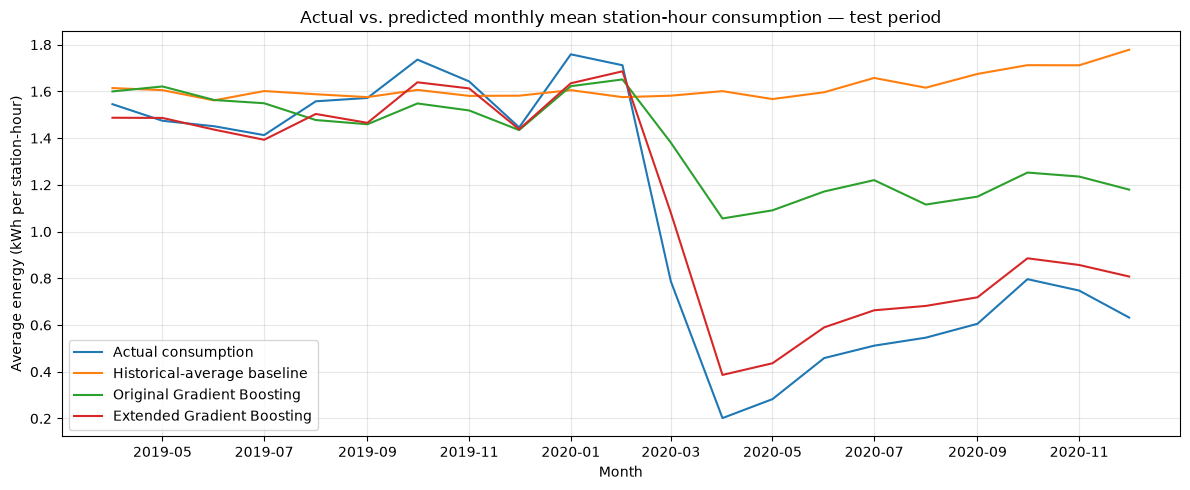

,Year,Model,MAE (kWh),RMSE (kWh),Bias (%)
0,2019,Historical-average baseline,1.443,2.116,3.388
1,2019,Original Gradient Boosting,1.395,2.088,-0.799
2,2019,Random Forest,1.468,2.153,0.209
3,2019,Extended Gradient Boosting,1.339,2.043,-2.623
4,2020,Historical-average baseline,1.526,2.159,114.321
5,2020,Original Gradient Boosting,1.222,1.787,66.339
6,2020,Random Forest,1.156,1.704,45.757
7,2020,Extended Gradient Boosting,0.925,1.587,15.052


In [23]:
# Cell 18: Visualize monthly demand and evaluate the 2019–2020 demand shift

# Display the observed 2020 demand change and the models' monthly predictions.
monthly = final_evaluation.copy()
monthly["Month"] = monthly["Hour"].dt.to_period("M").dt.to_timestamp()
monthly_average = monthly.groupby("Month").agg(
    Actual=("Energy (kWh)", "mean"),
    Baseline=("Baseline Prediction", "mean"),
    Gradient_Boosting=("Model Prediction", "mean"),
    Extended_GB=("Extended Prediction", "mean"),
).reset_index()
plt.figure(figsize=(12, 5))
for column, label in [
    ("Actual", "Actual consumption"),
    ("Baseline", "Historical-average baseline"),
    ("Gradient_Boosting", "Original Gradient Boosting"),
    ("Extended_GB", "Extended Gradient Boosting"),
]:
    plt.plot(monthly_average["Month"], monthly_average[column], label=label)
plt.title("Actual vs. predicted monthly mean station-hour consumption — test period")
plt.ylabel("Average energy (kWh per station-hour)")
plt.xlabel("Month")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Report year-by-year test performance and aggregate bias.
final_evaluation["Year"] = final_evaluation["Hour"].dt.year
yearly_results = []
for year, period in final_evaluation.groupby("Year"):
    truth = period["Energy (kWh)"].to_numpy()
    for name, column in model_columns.items():
        pred = period[column].to_numpy()
        residual = truth - pred
        yearly_results.append({
            "Year": year, "Model": name,
            "MAE (kWh)": np.abs(residual).mean(),
            "RMSE (kWh)": np.sqrt(np.mean(residual**2)),
            "Bias (%)": (pred.sum() - truth.sum()) / truth.sum() * 100
        })
display(pd.DataFrame(yearly_results).round(3))


### Interpreting the 2019–2020 changes

Forecast errors and aggregate bias vary between 2019 and 2020 in the test-period evaluation. This suggests that patterns learned from historical charging activity may not remain stable over time. Changes in station availability, user behaviour, or external conditions could contribute, but the data and models here do not establish a specific cause. These results motivate periodic model monitoring and retraining.

Station: PALO ALTO CA / HAMILTON #2
Date: 2019-04-22
Hourly predictions: 24


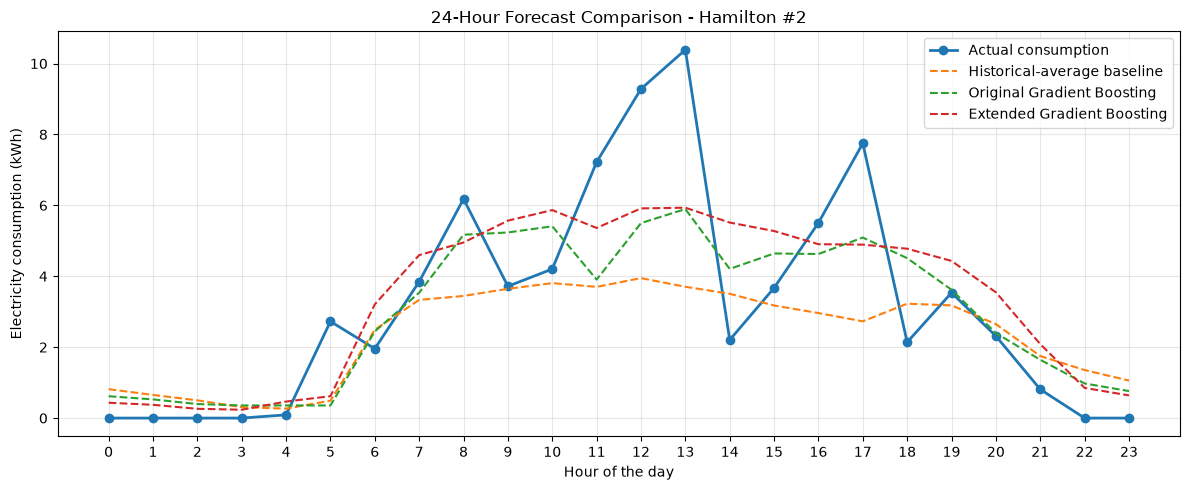

Actual daily consumption (kWh): 77.54


,Model,MAE (kWh),RMSE (kWh),Predicted Total (kWh)
0,Baseline,1.624,2.407,56.696
1,Original Gradient Boosting,1.345,1.802,72.184
2,Extended Gradient Boosting,1.505,1.867,80.711


In [24]:
# Cell 19: Plot and evaluate a complete example 24-hour forecast

station = "PALO ALTO CA / HAMILTON #2"
forecast_day = pd.Timestamp("2019-04-22")

# Select hourly observations
day_comparison = final_evaluation[
    (final_evaluation["Station Name"] == station) &
    (final_evaluation["Hour"].dt.normalize() == forecast_day)
].sort_values("Hour")

print("Station:", station)
print("Date:", forecast_day.date())
print("Hourly predictions:", len(day_comparison))

# Plot actual consumption and model predictions
plt.figure(figsize=(12, 5))

plt.plot(
    day_comparison["Hour"].dt.hour,
    day_comparison["Energy (kWh)"],
    label="Actual consumption",
    marker="o",
    linewidth=2
)

plt.plot(
    day_comparison["Hour"].dt.hour,
    day_comparison["Baseline Prediction"],
    label="Historical-average baseline",
    linestyle="--"
)

plt.plot(
    day_comparison["Hour"].dt.hour,
    day_comparison["Model Prediction"],
    label="Original Gradient Boosting",
    linestyle="--"
)

plt.plot(
    day_comparison["Hour"].dt.hour,
    day_comparison["Extended Prediction"],
    label="Extended Gradient Boosting",
    linestyle="--"
)

plt.xlabel("Hour of the day")
plt.ylabel("Electricity consumption (kWh)")
plt.title("24-Hour Forecast Comparison - Hamilton #2")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

results = []

actual = day_comparison["Energy (kWh)"].to_numpy()

for model_name, column in [
    ("Baseline", "Baseline Prediction"),
    ("Original Gradient Boosting", "Model Prediction"),
    ("Extended Gradient Boosting", "Extended Prediction")
]:
    predicted = day_comparison[column].to_numpy()
    errors = actual - predicted

    results.append({
        "Model": model_name,
        "MAE (kWh)": np.mean(np.abs(errors)),
        "RMSE (kWh)": np.sqrt(np.mean(errors ** 2)),
        "Predicted Total (kWh)": predicted.sum()
    })

daily_model_results = pd.DataFrame(results)

print("Actual daily consumption (kWh):", round(actual.sum(), 2))
display(daily_model_results.round(3))


In [25]:
# Cell 20: Evaluate complete 24-hour station-days and identify excluded short stations

# Use the final testing dataset with all model predictions
daily_data = final_evaluation.copy()

# Extract calendar day
daily_data["Day"] = daily_data["Hour"].dt.normalize()

# Models to compare
models = {
    "Baseline": "Baseline Prediction",
    "Original_GB": "Model Prediction",
    "Extended_GB": "Extended Prediction"
}

# Calculate hourly errors for each model
for name, column in models.items():
    error = daily_data["Energy (kWh)"] - daily_data[column]

    daily_data[f"{name}_Absolute_Error"] = error.abs()
    daily_data[f"{name}_Squared_Error"] = error ** 2

# Prepare daily aggregation
aggregations = {
    "Hours": ("Hour", "nunique"),
    "Actual_Daily_Total": ("Energy (kWh)", "sum")
}

for name, column in models.items():
    aggregations[f"{name}_MAE"] = (
        f"{name}_Absolute_Error", "mean"
    )
    aggregations[f"{name}_MSE"] = (
        f"{name}_Squared_Error", "mean"
    )
    aggregations[f"{name}_Daily_Total"] = (column, "sum")

# Calculate results for each station and day
daily_performance = (
    daily_data.groupby(["Station Name", "Day"])
    .agg(**aggregations)
    .reset_index()
)

# Keep only complete 24-hour days
daily_performance = daily_performance[
    daily_performance["Hours"] == 24
].copy()

# Calculate daily RMSE and absolute daily-total error
for name in models:
    daily_performance[f"{name}_RMSE"] = np.sqrt(
        daily_performance[f"{name}_MSE"]
    )

    daily_performance[f"{name}_Daily_Total_Error"] = (
        daily_performance[f"{name}_Daily_Total"]
        - daily_performance["Actual_Daily_Total"]
    ).abs()

print("Complete station-days evaluated:",
      len(daily_performance))

print("Stations evaluated:",
      daily_performance["Station Name"].nunique())

# Compare performance across complete station-days
results = []

for name in models:
    results.append({
        "Model": name,
        "Average Daily MAE (kWh)":
            daily_performance[f"{name}_MAE"].mean(),
        "Average Daily RMSE (kWh)":
            daily_performance[f"{name}_RMSE"].mean(),
        "Average Daily Total Error (kWh)":
            daily_performance[f"{name}_Daily_Total_Error"].mean()
    })

daily_summary = pd.DataFrame(results)

display(daily_summary.round(3))

# Check how often Extended GB is better
better_than_original = (
    daily_performance["Extended_GB_MAE"]
    < daily_performance["Original_GB_MAE"]
)

better_than_baseline = (
    daily_performance["Extended_GB_MAE"]
    < daily_performance["Baseline_MAE"]
)

print("\nExtended GB outperforms Original GB on:",
      round(better_than_original.mean() * 100, 2),
      "% of complete station-days")

print("Extended GB outperforms Baseline on:",
      round(better_than_baseline.mean() * 100, 2),
      "% of complete station-days")

# Stations in the hourly testing dataset
all_stations = set(daily_data["Station Name"].unique())

# Stations with at least one complete 24-hour day
complete_stations = set(
    daily_performance["Station Name"].unique()
)

# Identify excluded stations
excluded_stations = sorted(all_stations - complete_stations)

print("Total testing stations:", len(all_stations))
print("Stations with complete days:", len(complete_stations))
print("Stations without complete days:", len(excluded_stations))

# Display excluded stations and their observation periods
display(
    daily_data[
        daily_data["Station Name"].isin(excluded_stations)
    ]
    .groupby("Station Name")
    .agg(
        First_Hour=("Hour", "min"),
        Last_Hour=("Hour", "max"),
        Observations=("Hour", "count")
    )
)


Complete station-days evaluated: 19136
Stations evaluated: 41


,Model,Average Daily MAE (kWh),Average Daily RMSE (kWh),Average Daily Total Error (kWh)
0,Baseline,1.490,1.969,22.096
1,Original_GB,1.298,1.742,16.689
2,Extended_GB,1.106,1.552,12.416



Extended GB outperforms Original GB on: 77.29 % of complete station-days
Extended GB outperforms Baseline on: 78.67 % of complete station-days
Total testing stations: 46
Stations with complete days: 41
Stations without complete days: 5


,First_Hour,Last_Hour,Observations
Station Name,,,
PALO ALTO CA / SHERMAN 11,2020-12-29 09:00:00,2020-12-29 11:00:00,3
PALO ALTO CA / SHERMAN 15,2020-12-26 13:00:00,2020-12-26 15:00:00,3
PALO ALTO CA / SHERMAN 17,2020-12-29 09:00:00,2020-12-29 10:00:00,2
PALO ALTO CA / SHERMAN 5,2020-12-25 16:00:00,2020-12-25 17:00:00,2
PALO ALTO CA / SHERMAN 9,2020-12-13 12:00:00,2020-12-13 13:00:00,2


In [26]:
# Cell 21: Check station-level forecast performance

# Compare extended-model MAE to the baseline at each charging station.
station_errors = final_evaluation.copy()
station_errors["Baseline_Error"] = (
    station_errors["Energy (kWh)"] - station_errors["Baseline Prediction"]
).abs()
station_errors["Extended_Error"] = (
    station_errors["Energy (kWh)"] - station_errors["Extended Prediction"]
).abs()
station_summary = station_errors.groupby(["Station Name", "Station Type"]).agg(
    Observations=("Hour", "count"),
    Baseline_MAE=("Baseline_Error", "mean"),
    Extended_MAE=("Extended_Error", "mean"),
).reset_index()
station_summary["Improvement (%)"] = np.where(
    station_summary["Baseline_MAE"] > 0,
    100 * (station_summary["Baseline_MAE"] - station_summary["Extended_MAE"])
    / station_summary["Baseline_MAE"],
    np.nan,
)
print("Stations with lower Extended GB MAE than baseline:",
      (station_summary["Extended_MAE"] < station_summary["Baseline_MAE"]).sum(),
      "out of", len(station_summary))
display(station_summary.sort_values("Improvement (%)").round(3))


Stations with lower Extended GB MAE than baseline: 44 out of 46


,Station Name,Station Type,Observations,Baseline_MAE,Extended_MAE,Improvement (%)
29,PALO ALTO CA / SHERMAN 15,New,3,2.333,2.390,-2.426
27,PALO ALTO CA / SHERMAN 11,New,3,2.720,2.750,-1.081
38,PALO ALTO CA / SHERMAN 9,New,2,0.837,0.826,1.313
30,PALO ALTO CA / SHERMAN 17,New,2,2.052,1.973,3.833
34,PALO ALTO CA / SHERMAN 5,New,2,0.878,0.835,4.966
10,PALO ALTO CA / CAMBRIDGE #5,Existing,14874,1.391,1.292,7.099
41,PALO ALTO CA / TED THOMPSON #3,Existing,14874,1.206,1.106,8.264
8,PALO ALTO CA / CAMBRIDGE #3,Existing,14874,1.338,1.217,9.016
23,PALO ALTO CA / RINCONADA LIB 1,Existing,10503,1.510,1.340,11.256
42,PALO ALTO CA / TED THOMPSON #4,Existing,14869,1.019,0.900,11.709
